<div align="center">

# WEEK 04
## PRODUCT PERFORMANCE & DEMAND PATTERNS

### CadetX Virtual Work Experience
### Heavy Supplier, Inventory & Warehouse Analytics

</div>

---

| | |
|---|---|
| **Prepared by** | Keren Oyem |
| **Role** | Data Analyst (Scrum Master, Week 4) |
| **Sprint** | Week 4 · Fri 13 Nov – Thu 19 Nov 2026 |
| **Catalogue tasks** | B1 Product Performance Analysis · B2 Fast-Moving Product Identification · B7 ABC / Pareto Product Classification · B9 Product Demand Trend Analysis |
| **Data source** | `data/processed/*.parquet` (the clean layer from Week 2) |
| **Helper module** | `src/product_analysis.py` |
| **Tools** | Python, pandas, NumPy, statsmodels (STL), matplotlib |

## Objective

Explain which products drive revenue, margin and volume, classify them, and describe demand trends and seasonality. The output feeds Week 5 (inventory health, slow and dead stock), Week 9 (forecasting by ABC-XYZ class) and the Week 11 dashboards.

## Data used

| Table | Use |
|---|---|
| `sales_orders_lines` | quantity, `line_total` (revenue before GST) |
| `sales_orders_header` | order date, branch, `is_cancelled` flag |
| `products` | name, category, brand, machine type, `unit_cost` |
| `branches` | branch city label |
| `inventory_master` | the 180 product-branch pairs (so pairs that never sold still appear) |

## Assumptions (carried from the Week 2 issue log)

1. **Cancelled sales orders are excluded** everywhere (`is_cancelled = True`, issue I19).
2. **Revenue = `line_total`, before GST.** GST is tax collected, not income.
3. **Cost of goods = quantity × `products.unit_cost`**, and **gross margin = revenue − cost of goods.** Margin is therefore an *estimate* built on the product master cost, not an accounting figure.
4. **Branch = the branch on the sales order header.**
5. **Demand = units sold (quantity) per calendar month**, by `order_date`. Months with no sales count as zero demand.
6. `customers.total_purchase_value` is **not used** (issue I18).

## Results summary

*The final numbers are printed automatically in Section 5 ("Key findings"). After you run the notebook top to bottom, paste those lines here so a reviewer sees the results first.*

## How each task is laid out

Objective and approach → code cells, each followed by a **"Reading the output"** note → task summary. Every chart has a title, units and a one-line takeaway written from the data.

> **About the notes.** The "Reading the output" notes explain what to look at. The numbers on screen are the authority. After you run the notebook, add one sentence of your own interpretation under each note.

## Contents

0. Setup and base dataset · 1. B1 Product performance · 2. B7 ABC-XYZ · 3. B2 Velocity · 4. B9 Trend and seasonality · 5. Key findings, conclusions and next steps

---
## 0. Setup and base dataset

**Objective.** Load the clean Parquet tables, build one sales-line dataset (`base`) and prove it reconciles to the order headers before any analysis.

**Approach.**
* Find the project root (the folder that contains `src/`) so the notebook works from any folder.
* Import `src.product_analysis` and reload it, so edits to the helper file are picked up without restarting.
* Join lines → header → products → branches, drop cancelled orders, add revenue, cost and margin.
* Reconcile: delivered orders, lines and revenue must equal the header totals.

In [1]:
import os, sys, importlib, calendar
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the project root: the folder that contains src/
ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import src.product_analysis as pa
importlib.reload(pa)          # pick up edits to the helper file

PROCESSED_DIR = Path(os.environ.get("PROCESSED_DIR", ROOT / "data" / "processed"))
WEEK_DIR = Path(os.environ.get("WEEK_DIR", ROOT / "week-04"))     # CSV outputs
CHART_DIR = WEEK_DIR / "charts"                                   # PNG charts
CHART_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.options.display.float_format = "{:,.2f}".format
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

print("Project root :", ROOT)
print("Processed    :", PROCESSED_DIR)
print("Outputs      :", WEEK_DIR)

Project root : C:\Users\HP\Desktop\keren\my_project
Processed    : C:\Users\HP\Desktop\keren\my_project\data\processed
Outputs      : C:\Users\HP\Desktop\keren\my_project\week-04


**Reading the output.** Three paths. Check that *Project root* is your project folder and *Processed* points at `data/processed`. If a `FileNotFoundError` appears later, run `python -m src.cleaning` first to rebuild the Parquet files.

In [2]:
tables = pa.load_tables(PROCESSED_DIR)
base = pa.build_sales_base(tables)
MONTHS = pa.month_range(base)
PERIOD = f"{base['order_date'].min():%b %Y} to {base['order_date'].max():%b %Y}"

print("Base dataset:", base.shape[0], "order lines x", base.shape[1], "columns")
print("Period      :", PERIOD, f"({len(MONTHS)} months)")
base.head()

Base dataset: 117656 order lines x 23 columns
Period      : Jan 2019 to Dec 2024 (72 months)


,so_id,line_number,product_id,quantity,unit_price,gst_rate,line_total,customer_id,branch_id,order_date,is_cancelled,product_name,category,machine_type,brand,unit_cost,branch,order_month,year,month,revenue,cogs,gross_margin
0,SO-990591,1,P018,19,11300,28,214700,C0070,AHM001,2022-05-24,False,Wheel Rim WR-24,Undercarriage,Bulldozer,CAT,8200,Ahmedabad,2022-05-01,2022,5,"214,700.00","155,800.00","58,900.00"
1,SO-990591,2,P026,2,310,18,620,C0070,AHM001,2022-05-24,False,Grease Cartridge GC-5,Lubricants,All,Generic,180,Ahmedabad,2022-05-01,2022,5,620.00,360.00,260.00
2,SO-990591,3,P026,3,310,18,930,C0070,AHM001,2022-05-24,False,Grease Cartridge GC-5,Lubricants,All,Generic,180,Ahmedabad,2022-05-01,2022,5,930.00,540.00,390.00
3,SO-990591,4,P013,9,1450,18,13050,C0070,AHM001,2022-05-24,False,Seal Kit SK-15,Seals,Excavator,CAT,950,Ahmedabad,2022-05-01,2022,5,"13,050.00","8,550.00","4,500.00"
4,SO-990591,5,P004,3,39800,28,119400,C0070,AHM001,2022-05-24,False,Track Chain TC-45,Undercarriage,Bulldozer,Volvo,32500,Ahmedabad,2022-05-01,2022,5,"119,400.00","97,500.00","21,900.00"


**Reading the output.** One row per delivered sales-order line, with product, branch, `revenue`, `cogs` and `gross_margin` columns added. The period line gives the first and last order and the number of months, which every monthly calculation uses.

In [3]:
recon = pa.reconcile_base(base, tables)
display(recon)

# A partial last month would look like a false decline in the trend work.
orders_per_month = base.groupby("order_month")["so_id"].nunique()
print("Orders in the last 3 months (check the last month is not partial):")
display(orders_per_month.tail(3).to_frame("orders"))

,check,base_value,expected_value,difference,status
0,Delivered orders: base vs header,"18,033.00","18,033.00",0.00,PASS
1,Order lines: base vs lines table,"117,656.00","117,656.00",0.00,PASS
2,Revenue before GST: base vs header total_order...,"22,958,987,430.00","22,958,987,430.00",0.00,PASS
3,Lines with no product match,0.00,0.00,0.00,PASS
4,Lines with no branch match,0.00,0.00,0.00,PASS


Orders in the last 3 months (check the last month is not partial):


,orders
order_month,
2024-10-01,248
2024-11-01,261
2024-12-01,223


**Reading the output.**
* **Reconciliation.** Every row should say `PASS`: the base has the same number of delivered orders and lines as the headers and lines tables, revenue equals the header `total_order_value`, and no line lacks a product or branch. A `CHECK` means a join or filter is wrong; fix it before going on.
* **Last 3 months.** If the final month has far fewer orders than the one before it, it is probably incomplete and should be dropped from trend work.

In [4]:
kpis = pa.overall_kpis(base)
kpis

,value
first_order_date,2019-01-01
last_order_date,2024-12-31
delivered_orders,18033
order_lines,117656
units_sold,1234939
revenue_inr,"22,958,987,430.00"
gross_margin_inr,"4,950,006,740.00"
gross_margin_pct,21.56
avg_order_value_inr,"1,273,165.17"
products_sold,30


**Reading the output.** The headline numbers for the whole period: orders, units, revenue, gross margin and its percentage, and average order value (AOV = revenue ÷ delivered orders). Everything later splits these totals by product, category, branch and year.

---
## 1. Task B1: Product performance analysis

**Objective.** Show how revenue, units, gross margin and AOV differ by product, category, brand, machine type, branch and year, and test the 80/20 rule with Pareto charts.

**Why it matters.** It tells the business which products carry the revenue, and whether the picture is the same in every branch.

**Approach.**
1. Summarise by product, then by each other dimension.
2. Build Pareto tables for revenue and margin.
3. Repeat the 80% test inside each branch.

> With only 30 products, "the top 20%" is 6 products, so the Pareto result is coarse. We report how many products reach 80% rather than forcing a round number.

In [5]:
by_product = pa.summarise_by(base, ["product_id", "product_name", "category", "brand", "machine_type"])
by_product.to_csv(WEEK_DIR / "product_performance_by_product.csv", index=False)
by_product.head(10)

,product_id,product_name,category,brand,machine_type,revenue,units,gross_margin,orders,order_lines,margin_pct,aov,revenue_share_pct
0,P015,Engine Block EB-600,Engine,Komatsu,Excavator,"4,856,985,000.00",40815,"959,152,500.00",3411,3851,19.75,"1,423,918.21",21.16
1,P014,Transmission Assembly TA-800,Transmission,Volvo,Bulldozer,"3,387,929,000.00",40574,"608,610,000.00",3462,3889,17.96,"978,604.56",14.76
2,P021,Boom Cylinder BC-400,Hydraulic,Komatsu,Excavator,"1,934,116,800.00",41864,"443,758,400.00",3481,3936,22.94,"555,621.03",8.42
3,P019,Swing Motor SWM-350,Hydraulic,Volvo,Excavator,"1,653,411,400.00",41543,"357,269,800.00",3476,3955,21.61,"475,664.96",7.20
4,P004,Track Chain TC-45,Undercarriage,Volvo,Bulldozer,"1,627,461,800.00",40891,"298,504,300.00",3392,3856,18.34,"479,794.16",7.09
5,P010,Turbocharger TB-900,Engine,CAT,Excavator,"1,475,990,800.00",42292,"253,752,000.00",3542,3980,17.19,"416,711.12",6.43
6,P011,Hydraulic Cylinder HC-200,Hydraulic,Tata Hitachi,Excavator,"1,161,766,800.00",42093,"256,767,300.00",3595,4030,22.10,"323,161.84",5.06
7,P001,Hydraulic Pump HP-300,Hydraulic,CAT,Excavator,"1,011,948,000.00",41304,"229,237,200.00",3499,3948,22.65,"289,210.63",4.41
8,P030,Fuel Pump FP-350,Engine,Volvo,Excavator,"910,930,500.00",41595,"228,772,500.00",3509,3929,25.11,"259,598.32",3.97
9,P022,Control Valve CV-75,Hydraulic,CAT,Excavator,"697,919,300.00",41297,"169,317,700.00",3493,3924,24.26,"199,805.12",3.04


**Reading the output.** The ten best products by revenue, with units, gross margin, margin %, number of orders, AOV and revenue share. Compare the rank by revenue with the rank by margin %: a product can sell a lot and earn little. The full 30-row table is saved to `week-04/product_performance_by_product.csv`.

In [6]:
dims = {"category": ["category"], "brand": ["brand"], "machine_type": ["machine_type"],
        "branch": ["branch_id", "branch"], "year": ["year"]}
dim_tables = {name: pa.summarise_by(base, cols) for name, cols in dims.items()}

yr = dim_tables["year"].sort_values("year").reset_index(drop=True)
yr["revenue_yoy_pct"] = yr["revenue"].pct_change() * 100
dim_tables["year"] = yr

for name, t in dim_tables.items():
    print(f"\n=== By {name} ===")
    display(t)
    t.to_csv(WEEK_DIR / f"performance_by_{name}.csv", index=False)


=== By category ===


,category,revenue,units,gross_margin,orders,order_lines,margin_pct,aov,revenue_share_pct
0,Engine,"7,585,962,300.00",165182,"1,526,685,000.00",10056,15656,20.13,"754,371.75",33.04
1,Hydraulic,"6,520,288,500.00",250257,"1,476,163,720.00",12607,23776,22.64,"517,195.88",28.40
2,Transmission,"3,387,929,000.00",40574,"608,610,000.00",3462,3889,17.96,"978,604.56",14.76
3,Undercarriage,"3,016,239,400.00",161405,"690,379,900.00",9905,15395,22.89,"304,516.85",13.14
4,Electrical,"1,165,698,900.00",123682,"279,620,400.00",8339,11751,23.99,"139,788.81",5.08
5,Cooling,"426,054,000.00",41770,"100,248,000.00",3544,4006,23.53,"120,218.40",1.86
6,Cabin,"322,564,350.00",41091,"92,454,750.00",3480,3942,28.66,"92,690.91",1.40
7,Sensors,"168,672,900.00",42702,"51,242,400.00",3506,3973,30.38,"48,109.78",0.73
8,Brakes,"101,795,050.00",41549,"27,006,850.00",3517,3989,26.53,"28,943.72",0.44
9,Filters,"81,600,240.00",82629,"28,983,750.00",6275,7890,35.52,"13,004.02",0.36



=== By brand ===


,brand,revenue,units,gross_margin,orders,order_lines,margin_pct,aov,revenue_share_pct
0,Volvo,"8,705,457,200.00",245426,"1,784,078,750.00",12426,23293,20.49,"700,584.03",37.92
1,Komatsu,"6,867,056,020.00",165450,"1,430,701,220.00",10045,15673,20.83,"683,629.27",29.91
2,CAT,"4,341,564,350.00",290117,"956,543,650.00",13387,27528,22.03,"324,311.97",18.91
3,Tata Hitachi,"1,931,807,000.00",162979,"464,468,700.00",10105,15729,24.04,"191,173.38",8.41
4,JCB,"988,052,090.00",248398,"266,936,510.00",12489,23713,27.02,"79,113.79",4.30
5,Generic,"125,050,770.00",122569,"47,277,910.00",8285,11720,37.81,"15,093.64",0.54



=== By machine_type ===


,machine_type,revenue,units,gross_margin,orders,order_lines,margin_pct,aov,revenue_share_pct
0,Excavator,"14,738,540,870.00",661609,"3,199,036,370.00",16708,62958,21.71,"882,124.78",64.20
1,Bulldozer,"6,404,168,400.00",201979,"1,298,989,900.00",11282,19284,20.28,"567,644.78",27.89
2,Loader,"1,118,857,890.00",207371,"278,035,690.00",11372,19818,24.85,"98,387.08",4.87
3,Dumper,"604,150,300.00",40547,"139,887,150.00",3412,3829,23.15,"177,066.32",2.63
4,Crane,"61,126,200.00",42156,"19,813,320.00",3534,3983,32.41,"17,296.60",0.27
5,All,"32,143,770.00",81277,"14,244,310.00",6137,7784,44.31,"5,237.70",0.14



=== By branch ===


,branch_id,branch,revenue,units,gross_margin,orders,order_lines,margin_pct,aov,revenue_share_pct
0,CHN001,Chennai,"4,682,202,010.00",253921,"1,011,454,560.00",3677,24202,21.60,"1,273,375.58",20.39
1,KOL001,Kolkata,"4,339,861,320.00",230868,"935,144,800.00",3413,21989,21.55,"1,271,567.92",18.90
2,AHM001,Ahmedabad,"3,986,314,570.00",214223,"858,448,080.00",3115,20425,21.53,"1,279,715.75",17.36
3,DEL001,Delhi,"3,500,031,300.00",185319,"752,552,770.00",2682,17511,21.50,"1,305,007.94",15.24
4,PUN001,Pune,"3,373,530,010.00",181633,"727,155,460.00",2668,17427,21.55,"1,264,441.53",14.69
5,HYD001,Hyderabad,"3,077,048,220.00",168975,"665,251,070.00",2478,16102,21.62,"1,241,746.66",13.40



=== By year ===


,year,revenue,units,gross_margin,orders,order_lines,margin_pct,aov,revenue_share_pct,revenue_yoy_pct
0,2019,"3,870,016,600.00",207925,"834,440,040.00",3031,19710,21.56,"1,276,811.81",16.86,NaN
1,2020,"3,917,532,120.00",212007,"845,098,840.00",3038,20205,21.57,"1,289,510.24",17.06,1.23
2,2021,"3,852,479,620.00",208269,"831,184,120.00",3038,19745,21.58,"1,268,097.31",16.78,-1.66
3,2022,"3,816,288,220.00",202242,"821,097,090.00",2948,19264,21.52,"1,294,534.67",16.62,-0.94
4,2023,"3,824,675,310.00",204638,"824,558,720.00",3022,19606,21.56,"1,265,610.63",16.66,0.22
5,2024,"3,677,995,560.00",199858,"793,627,930.00",2956,19126,21.58,"1,244,247.48",16.02,-3.84


**Reading the output.** One table per dimension. Look for: which category, brand and machine type lead on revenue and on margin %; whether branches differ in revenue and AOV; and the year table's `revenue_yoy_pct`, which shows growth or decline year on year. Each table is also saved as a CSV.

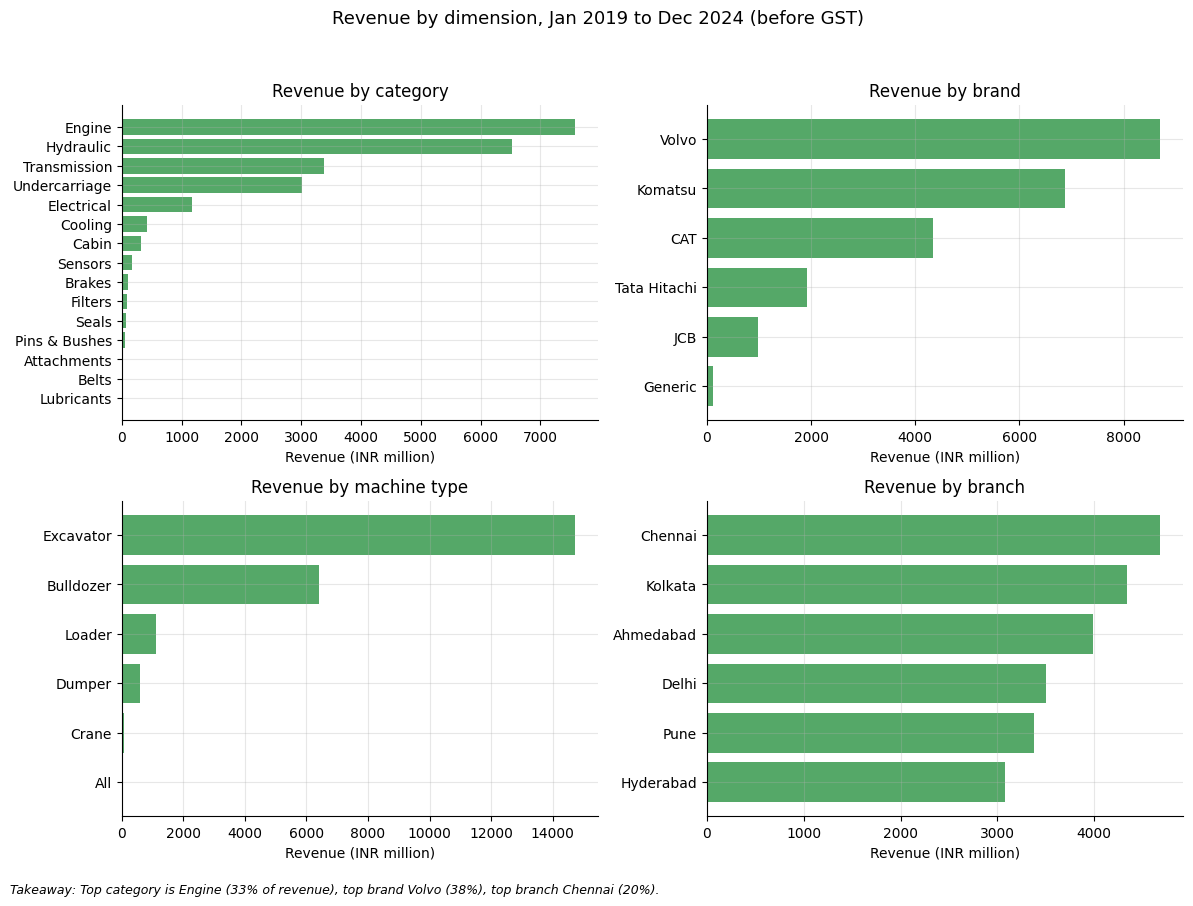

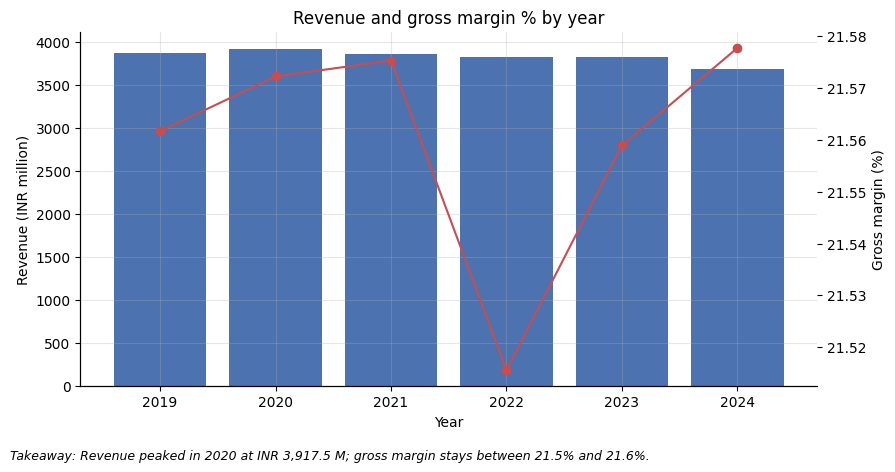

WindowsPath('C:/Users/HP/Desktop/keren/my_project/week-04/charts/b1_revenue_margin_by_year.png')

In [7]:
fig = pa.plot_bar_panel([
    ("Revenue by category", dim_tables["category"], "category"),
    ("Revenue by brand", dim_tables["brand"], "brand"),
    ("Revenue by machine type", dim_tables["machine_type"], "machine_type"),
    ("Revenue by branch", dim_tables["branch"], "branch"),
])
fig.suptitle(f"Revenue by dimension, {PERIOD} (before GST)", fontsize=13, y=1.03)
top = {k: dim_tables[k].iloc[0] for k in ["category", "brand", "machine_type", "branch"]}
pa.save_chart(fig, "b1_revenue_by_dimension",
    f"Top category is {top['category']['category']} ({top['category']['revenue_share_pct']:.0f}% of revenue), "
    f"top brand {top['brand']['brand']} ({top['brand']['revenue_share_pct']:.0f}%), "
    f"top branch {top['branch']['branch']} ({top['branch']['revenue_share_pct']:.0f}%).", CHART_DIR)

fig = pa.plot_year_bars(yr)
best = yr.loc[yr["revenue"].idxmax()]
pa.save_chart(fig, "b1_revenue_margin_by_year",
    f"Revenue peaked in {int(best['year'])} at {pa.inr_m(best['revenue'])}; gross margin stays between "
    f"{yr['margin_pct'].min():.1f}% and {yr['margin_pct'].max():.1f}%.", CHART_DIR)

**Reading the output.** Two charts. The first compares shares across category, brand, machine type and branch. The second shows revenue per year with the gross margin % line. If revenue is flat across years, that is a finding, not a failure: Week 9 forecasting will inherit a weak trend.

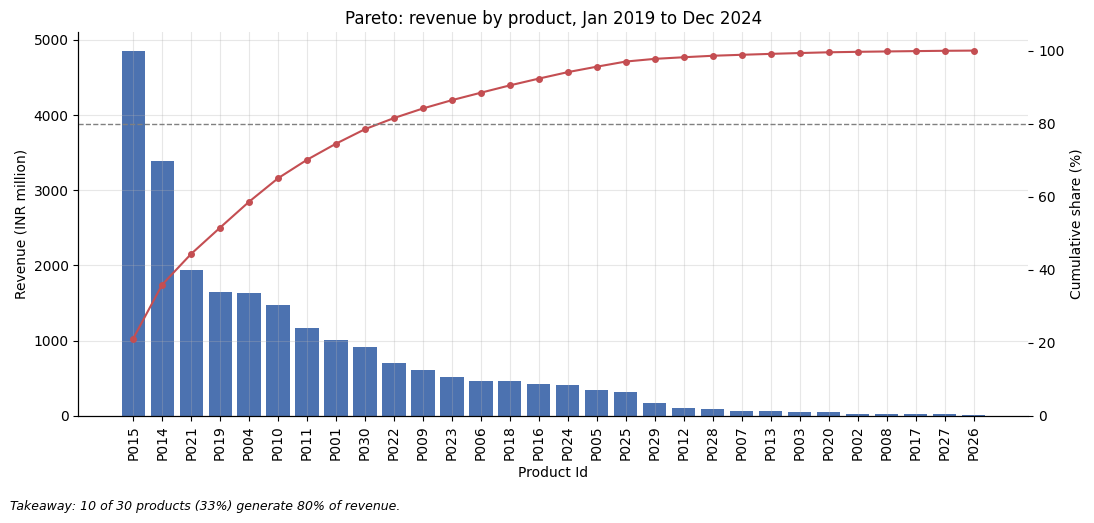

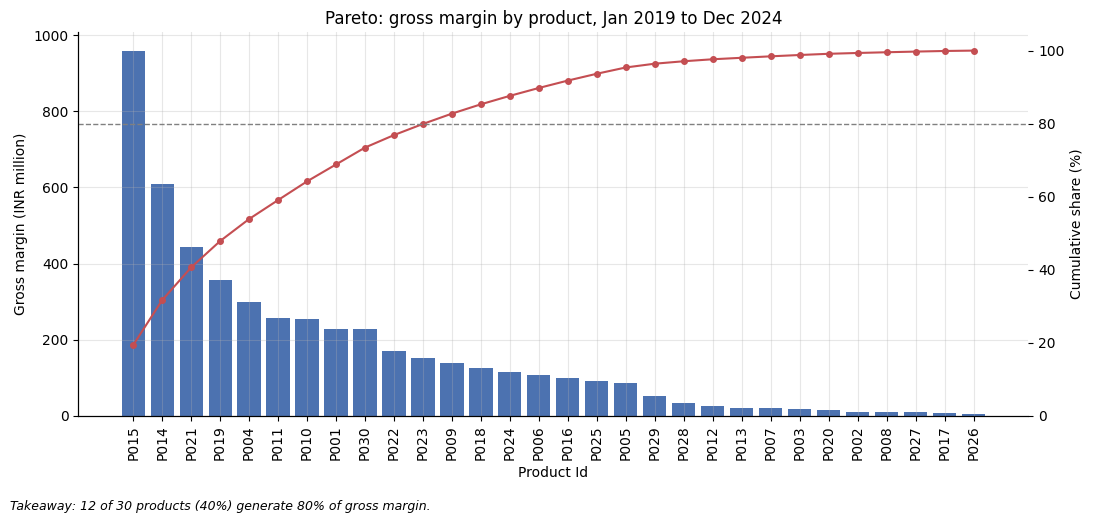

Products reaching 80% of revenue: P015, P014, P021, P019, P004, P010, P011, P001, P030, P022
Products reaching 80% of margin : P015, P014, P021, P019, P004, P011, P010, P001, P030, P022, P023, P009
Overlap between the two lists   : 10 products


In [8]:
par_rev = pa.pareto_table(by_product, "revenue")
par_mar = pa.pareto_table(by_product, "gross_margin")
n80_rev = pa.items_for_share(par_rev, 80)
n80_mar = pa.items_for_share(par_mar, 80)
n_prod = len(par_rev)

fig = pa.plot_pareto(par_rev, "product_id", "revenue",
                     f"Pareto: revenue by product, {PERIOD}", "Revenue (INR million)")
pa.save_chart(fig, "b1_pareto_revenue",
    f"{n80_rev} of {n_prod} products ({n80_rev / n_prod:.0%}) generate 80% of revenue.", CHART_DIR)

fig = pa.plot_pareto(par_mar, "product_id", "gross_margin",
                     f"Pareto: gross margin by product, {PERIOD}", "Gross margin (INR million)")
pa.save_chart(fig, "b1_pareto_margin",
    f"{n80_mar} of {n_prod} products ({n80_mar / n_prod:.0%}) generate 80% of gross margin.", CHART_DIR)

top_rev = par_rev.head(n80_rev)["product_id"].tolist()
top_mar = par_mar.head(n80_mar)["product_id"].tolist()
print("Products reaching 80% of revenue:", ", ".join(top_rev))
print("Products reaching 80% of margin :", ", ".join(top_mar))
print("Overlap between the two lists   :", len(set(top_rev) & set(top_mar)), "products")

**Reading the output.** Bars are products sorted by value; the red line is the cumulative share and the dashed line marks 80%. The takeaway states how many products reach 80% of revenue and of margin. The printed lists show whether the same products lead on both, which matters for ABC classification in Section 2.

In [9]:
rows = []
for (bid, bname), g in base.groupby(["branch_id", "branch"]):
    t = pa.pareto_table(pa.summarise_by(g, ["product_id"]), "revenue")
    n = pa.items_for_share(t, 80)
    top = t.head(n)["product_id"].tolist()
    rows.append({"branch_id": bid, "branch": bname, "revenue": g["revenue"].sum(),
                 "products_for_80pct": n,
                 "overlap_with_overall_top": len(set(top) & set(top_rev)),
                 "top_products": ", ".join(top)})
branch_pareto = pd.DataFrame(rows).sort_values("revenue", ascending=False)
branch_pareto.to_csv(WEEK_DIR / "pareto_by_branch.csv", index=False)
branch_pareto

,branch_id,branch,revenue,products_for_80pct,overlap_with_overall_top,top_products
1,CHN001,Chennai,"4,682,202,010.00",10,10,"P015, P014, P021, P019, P004, P010, P011, P001..."
4,KOL001,Kolkata,"4,339,861,320.00",10,10,"P015, P014, P021, P019, P004, P010, P011, P001..."
0,AHM001,Ahmedabad,"3,986,314,570.00",10,10,"P015, P014, P021, P004, P019, P010, P011, P001..."
2,DEL001,Delhi,"3,500,031,300.00",10,10,"P015, P014, P019, P021, P004, P010, P011, P001..."
5,PUN001,Pune,"3,373,530,010.00",10,10,"P015, P014, P021, P004, P019, P010, P011, P001..."
3,HYD001,Hyderabad,"3,077,048,220.00",10,10,"P015, P014, P021, P019, P004, P010, P011, P001..."


**Reading the output.** For each branch: how many products make up 80% of its revenue, and how many of them are also in the overall top list. If the numbers are similar and the overlap is high, every branch sells the same core products; if not, the product mix differs by branch and stock should be placed accordingly (Week 6).

In [10]:
prod_year = by_product[["product_id"]].merge(
    base.groupby(["product_id", "year"])["revenue"].sum().unstack("year").reset_index(),
    on="product_id", how="left")
prod_branch = base.groupby(["product_id", "branch"])["revenue"].sum().unstack("branch").reset_index()
prod_year.to_csv(WEEK_DIR / "revenue_product_by_year.csv", index=False)
prod_branch.to_csv(WEEK_DIR / "revenue_product_by_branch.csv", index=False)
display((prod_year.set_index("product_id") / 1e6).round(2).head(10))

,2019,2020,2021,2022,2023,2024
product_id,,,,,,
P015,813.60,831.57,809.32,822.29,825.74,754.46
P014,537.24,583.58,568.22,585.75,546.34,566.80
P021,326.17,315.27,348.07,330.19,298.22,316.19
P019,283.54,295.04,276.09,266.10,288.91,243.74
P004,298.14,258.42,271.71,263.91,269.41,265.86
P010,257.95,259.03,243.74,237.25,252.82,225.21
P011,200.24,199.13,190.19,189.25,191.82,191.13
P001,171.11,165.99,170.84,170.08,171.65,162.29
P030,155.34,158.45,139.33,154.26,147.17,156.39


**Reading the output.** Revenue (INR million) per product by year for the first ten products. Scan across a row for products that grow or shrink; Section 4 tests this formally. Both pivots (product × year and product × branch) are saved for the dashboards.

### Task B1: Summary

| Question | Answer (fill in from the output above) |
|---|---|
| Which products drive revenue? |P015, P014, P021, P019, P004, P010, P011, P001, P030, P022
 |
| How many products reach 80% of revenue and of margin? |10 |
| Do high-revenue products also have high margin %? | YES|
| Do branches differ in their core products? |NO |
| Is revenue growing, flat or falling by year? |Flat |

**Status: COMPLETED** once the table is filled in.

---
## 2. Task B7: ABC / Pareto classification combined with XYZ

**Objective.** Classify every product by *value* (ABC) and by *demand variability* (XYZ) and place it in a 9-cell ABC-XYZ matrix.

**Definitions.**

| Class | Rule |
|---|---|
| **A** | Products that take cumulative revenue (or margin) to 80%. |
| **B** | Products that take it from 80% to 95%. |
| **C** | The remaining 5%. |
| **X** | Steady demand: coefficient of variation (CV) of monthly units below the X cut-off. |
| **Y** | Variable demand: CV between the X and Y cut-offs. |
| **Z** | Erratic demand: CV above the Y cut-off (or no demand at all). |

CV = standard deviation ÷ mean of monthly units. Months with no sales count as zero.

**Approach.** Look at the real CV distribution *before* fixing the cut-offs, then classify at product level (30 products) and at product-branch level (180 series, used for Week 9 forecasting).

Distribution of CV across the 30 products:


,cv
count,30.00
mean,0.17
std,0.01
min,0.14
10%,0.15
25%,0.16
50%,0.17
75%,0.18
90%,0.18
max,0.19


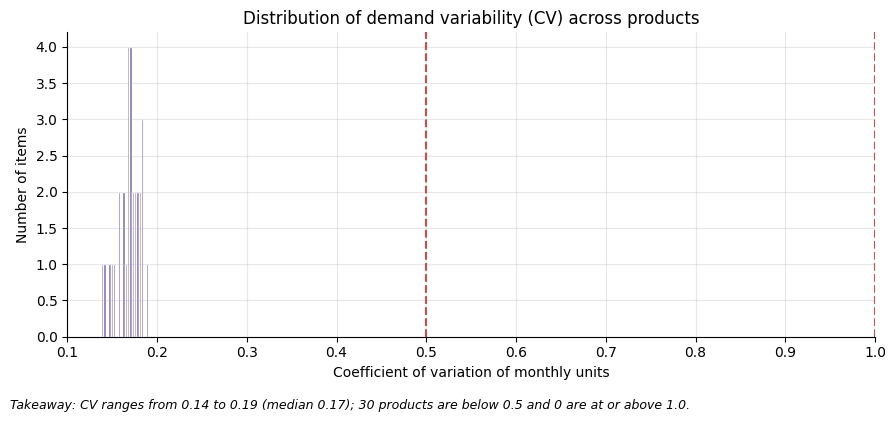

WindowsPath('C:/Users/HP/Desktop/keren/my_project/week-04/charts/b7_cv_distribution.png')

In [29]:
m_prod = pa.monthly_matrix(base, ["product_id"], "quantity", MONTHS,
                           universe=tables["products"][["product_id"]])
cv_prod = pa.cv_table(m_prod)

print("Distribution of CV across the 30 products:")
display(cv_prod["cv"].describe(percentiles=[.1, .25, .5, .75, .9]).to_frame("cv"))

fig = pa.plot_hist(cv_prod["cv"], (0.5, 1.0), "Distribution of demand variability (CV) across products",
                   "Coefficient of variation of monthly units")
fig.axes[0].set_xlim(0.10, 1.00)
pa.save_chart(fig, "b7_cv_distribution",
    f"CV ranges from {cv_prod['cv'].min():.2f} to {cv_prod['cv'].max():.2f} (median {cv_prod['cv'].median():.2f}); "
    f"{(cv_prod['cv'] < 0.5).sum()} products are below 0.5 and {(cv_prod['cv'] >= 1.0).sum()} are at or above 1.0.", CHART_DIR)

**Reading the output.** The CV summary and a histogram with the default cut-offs (0.5 and 1.0) as dashed lines. If nearly every product falls in one band, the default cut-offs separate nothing useful. In that case choose cut-offs from the data (for example the 33rd and 66th percentiles) and *state that choice* in the next cell. Whatever you choose, write down why.

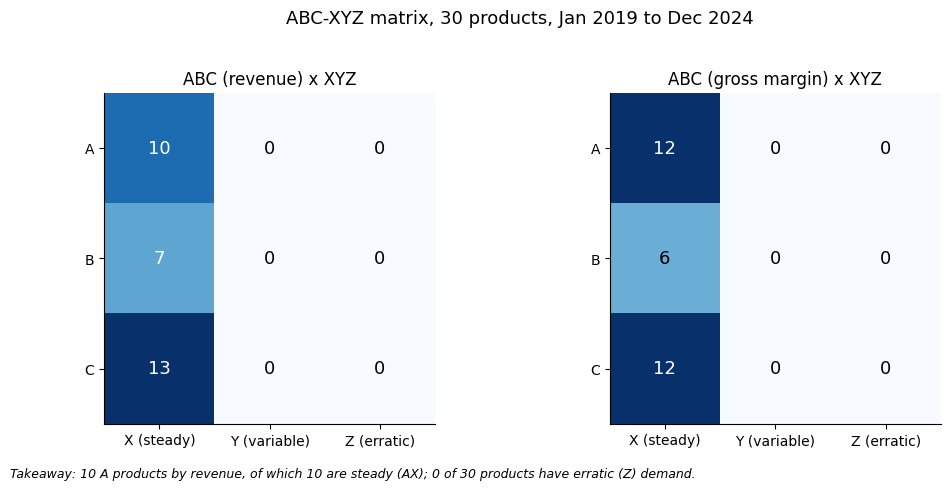

xyz,X,Y,Z
abc_revenue,,,
A,10,0,0
B,7,0,0
C,13,0,0


In [12]:
# ---- Classification settings: change here only, and document why ----------
A_CUT, B_CUT = 80, 95        # cumulative share (%) for A and B
X_CUT, Y_CUT = 0.5, 1.0      # CV cut-offs for X and Y (review against the histogram above)
# ---------------------------------------------------------------------------

abc_xyz = pa.classify_abc_xyz(base, ["product_id"], universe=tables["products"][["product_id"]],
                              x_cut=X_CUT, y_cut=Y_CUT, a_cut=A_CUT, b_cut=B_CUT, months=MONTHS)
abc_xyz = pa.attach_labels(abc_xyz, tables)

mat_rev = pa.abc_xyz_matrix(abc_xyz, "abc_revenue")
mat_mar = pa.abc_xyz_matrix(abc_xyz, "abc_margin")

fig = pa.plot_matrices([("ABC (revenue) x XYZ", mat_rev), ("ABC (gross margin) x XYZ", mat_mar)],
                       cbar_label="Number of products")
fig.suptitle(f"ABC-XYZ matrix, 30 products, {PERIOD}", fontsize=13, y=1.03)
n_a = int((abc_xyz["abc_revenue"] == "A").sum())
n_ax = int((abc_xyz["abc_xyz"] == "AX").sum())
n_z = int((abc_xyz["xyz"] == "Z").sum())
pa.save_chart(fig, "b7_abc_xyz_matrix",
    f"{n_a} A products by revenue, of which {n_ax} are steady (AX); {n_z} of 30 products have erratic (Z) demand.", CHART_DIR)
display(mat_rev)

**Reading the output.** Two 3 × 3 heatmaps (one for revenue-based ABC, one for margin-based ABC) with the number of products in each cell. The table below is the revenue version. Read the corners: **AX** (high value, steady) are the products to never run out of; **CZ** (low value, erratic) are candidates for lower stock or make-to-order. If every product sits in one XYZ column, revisit the cut-offs.

In [13]:
share_by_cell = (abc_xyz.groupby("abc_xyz")
                 .agg(products=("product_id", "count"), revenue=("revenue", "sum"),
                      product_list=("product_id", lambda s: ", ".join(s)))
                 .assign(revenue_share_pct=lambda d: d["revenue"] / d["revenue"].sum() * 100)
                 .sort_values("revenue", ascending=False))
share_by_cell

,products,revenue,product_list,revenue_share_pct
abc_xyz,,,,
AX,10,"18,718,459,400.00","P015, P014, P021, P019, P004, P010, P011, P001...",81.53
BX,7,"3,229,679,500.00","P009, P023, P006, P018, P016, P024, P005",14.07
CX,13,"1,010,848,530.00","P025, P029, P012, P028, P007, P013, P003, P020...",4.40


**Reading the output.** For each occupied cell: how many products, which ones, and what share of revenue they carry. Use it to name the products behind each corner of the matrix in the insight brief.

In [14]:
export_cols = ["product_id", "product_name", "category", "brand", "machine_type", "revenue", "units",
               "gross_margin", "revenue_share_pct", "abc_revenue", "abc_margin",
               "mean_monthly_units", "cv", "xyz", "abc_xyz", "abc_margin_xyz"]
abc_xyz[export_cols].to_csv(WEEK_DIR / "abc_xyz_classification.csv", index=False)
abc_xyz[export_cols].head(10)

,product_id,product_name,category,brand,machine_type,revenue,units,gross_margin,revenue_share_pct,abc_revenue,abc_margin,mean_monthly_units,cv,xyz,abc_xyz,abc_margin_xyz
0,P015,Engine Block EB-600,Engine,Komatsu,Excavator,"4,856,985,000.00",40815,"959,152,500.00",21.16,A,A,566.88,0.14,X,AX,AX
1,P014,Transmission Assembly TA-800,Transmission,Volvo,Bulldozer,"3,387,929,000.00",40574,"608,610,000.00",14.76,A,A,563.53,0.17,X,AX,AX
2,P021,Boom Cylinder BC-400,Hydraulic,Komatsu,Excavator,"1,934,116,800.00",41864,"443,758,400.00",8.42,A,A,581.44,0.18,X,AX,AX
3,P019,Swing Motor SWM-350,Hydraulic,Volvo,Excavator,"1,653,411,400.00",41543,"357,269,800.00",7.20,A,A,576.99,0.18,X,AX,AX
4,P004,Track Chain TC-45,Undercarriage,Volvo,Bulldozer,"1,627,461,800.00",40891,"298,504,300.00",7.09,A,A,567.93,0.17,X,AX,AX
5,P010,Turbocharger TB-900,Engine,CAT,Excavator,"1,475,990,800.00",42292,"253,752,000.00",6.43,A,A,587.39,0.16,X,AX,AX
6,P011,Hydraulic Cylinder HC-200,Hydraulic,Tata Hitachi,Excavator,"1,161,766,800.00",42093,"256,767,300.00",5.06,A,A,584.62,0.15,X,AX,AX
7,P001,Hydraulic Pump HP-300,Hydraulic,CAT,Excavator,"1,011,948,000.00",41304,"229,237,200.00",4.41,A,A,573.67,0.15,X,AX,AX
8,P030,Fuel Pump FP-350,Engine,Volvo,Excavator,"910,930,500.00",41595,"228,772,500.00",3.97,A,A,577.71,0.18,X,AX,AX
9,P022,Control Valve CV-75,Hydraulic,CAT,Excavator,"697,919,300.00",41297,"169,317,700.00",3.04,A,A,573.57,0.17,X,AX,AX


**Reading the output.** The deliverable `abc_xyz_classification.csv` is written to `week-04/`; the first ten rows are shown. Each product has its ABC (revenue and margin), CV, XYZ class and combined cell, ready for dashboards and Week 9.

In [15]:
pairs = tables["inventory_master"][["product_id", "branch_id"]]
abc_xyz_pb = pa.classify_abc_xyz(base, ["product_id", "branch_id"], universe=pairs,
                                 x_cut=X_CUT, y_cut=Y_CUT, a_cut=A_CUT, b_cut=B_CUT, months=MONTHS)
abc_xyz_pb = pa.attach_labels(abc_xyz_pb, tables)
abc_xyz_pb.to_csv(WEEK_DIR / "abc_xyz_product_branch.csv", index=False)

print("Product-branch series classified:", len(abc_xyz_pb))
display(pa.abc_xyz_matrix(abc_xyz_pb, "abc_revenue"))
display(pd.crosstab(abc_xyz_pb["branch"], abc_xyz_pb["abc_xyz"]))

Product-branch series classified: 180


xyz,X,Y,Z
abc_revenue,,,
A,56,1,0
B,41,1,0
C,79,2,0


abc_xyz,AX,AY,BX,BY,CX,CY
branch,,,,,,
Ahmedabad,9,0,8,0,13,0
Chennai,11,0,7,0,12,0
Delhi,9,0,6,0,14,1
Hyderabad,8,1,5,1,14,1
Kolkata,10,0,8,0,12,0
Pune,9,0,7,0,14,0


**Reading the output.** The same classification for each of the 180 product-branch series (saved as `abc_xyz_product_branch.csv`, used in Week 9 to choose a forecasting method per class). The first table is the 3 × 3 count; the second shows how each branch's series spread across the nine cells. Series with no sales at all are classed Z and C.

### Task B7: Summary

| Question | Answer (fill in from the output above) |
|---|---|
| Which products are AX (high value, steady)? |P015, P014, P021, P019, P004, P010, P011, P001 |
| Which are CZ (low value, erratic)? |none |
| Did you keep the default X/Y cut-offs? If not, why? |YES |
| Do revenue-ABC and margin-ABC agree? | NO|

**Status: COMPLETED** once the table is filled in and `abc_xyz_classification.csv` exists.

---
## 3. Task B2: Fast-moving product identification (velocity)

**Objective.** Rank products by how quickly and how often they sell.

**Measures.**
* **Units per month**: total units ÷ months in the period.
* **Order lines per month**: how many separate order lines contain the product.
* **Days with demand**: number of distinct days on which it sold.

**Velocity score.** The average percentile rank of the three measures × 100 (0 = slowest, 100 = fastest). Classes: top third **Fast**, middle third **Medium**, bottom third **Slow**, and **No sales** for items that never sold. Thirds are a convention; the score itself is the better measure.

The product-branch version is saved for Week 5 (slow and dead stock).

In [16]:
vel_prod = pa.velocity_table(base, ["product_id"], universe=tables["products"][["product_id"]])
vel_prod = pa.attach_labels(vel_prod, tables)
vel_prod = vel_prod.merge(abc_xyz[["product_id", "abc_revenue", "xyz", "abc_xyz"]], on="product_id", how="left")
vel_prod.to_csv(WEEK_DIR / "product_velocity.csv", index=False)

cols = ["product_id", "product_name", "units_per_month", "order_lines_per_month",
        "days_with_demand", "velocity_score", "velocity_class", "abc_xyz"]
print("Fastest 5:")
display(vel_prod[cols].head(5))
print("Slowest 5:")
display(vel_prod[cols].tail(5))

Fastest 5:


,product_id,product_name,units_per_month,order_lines_per_month,days_with_demand,velocity_score,velocity_class,abc_xyz
0,P011,Hydraulic Cylinder HC-200,584.62,55.97,1769,94.44,Fast,AX
1,P010,Turbocharger TB-900,587.39,55.28,1776,91.11,Fast,AX
2,P007,Hydraulic Hose HH-60,585.50,55.32,1775,90.00,Fast,CX
3,P016,Radiator RD-250,580.14,55.64,1756,85.56,Fast,BX
4,P003,Air Filter AF-120,579.33,55.40,1758,85.00,Fast,CX


Slowest 5:


,product_id,product_name,units_per_month,order_lines_per_month,days_with_demand,velocity_score,velocity_class,abc_xyz
25,P018,Wheel Rim WR-24,566.00,54.01,1725,24.44,Slow,BX
26,P014,Transmission Assembly TA-800,563.53,54.01,1720,21.11,Slow,AX
27,P009,Starter Motor SM-700,563.15,53.18,1726,18.89,Slow,BX
28,P024,Track Roller TR-60,548.42,52.99,1726,11.11,Slow,BX
29,P023,Idler Wheel IW-55,559.39,53.26,1703,10.00,Slow,BX


**Reading the output.** The five fastest and five slowest products with their three measures, score and class. The full table is saved as `product_velocity.csv` (Week 5 reuses it). Note whether the fastest products are also the A products from Section 2.

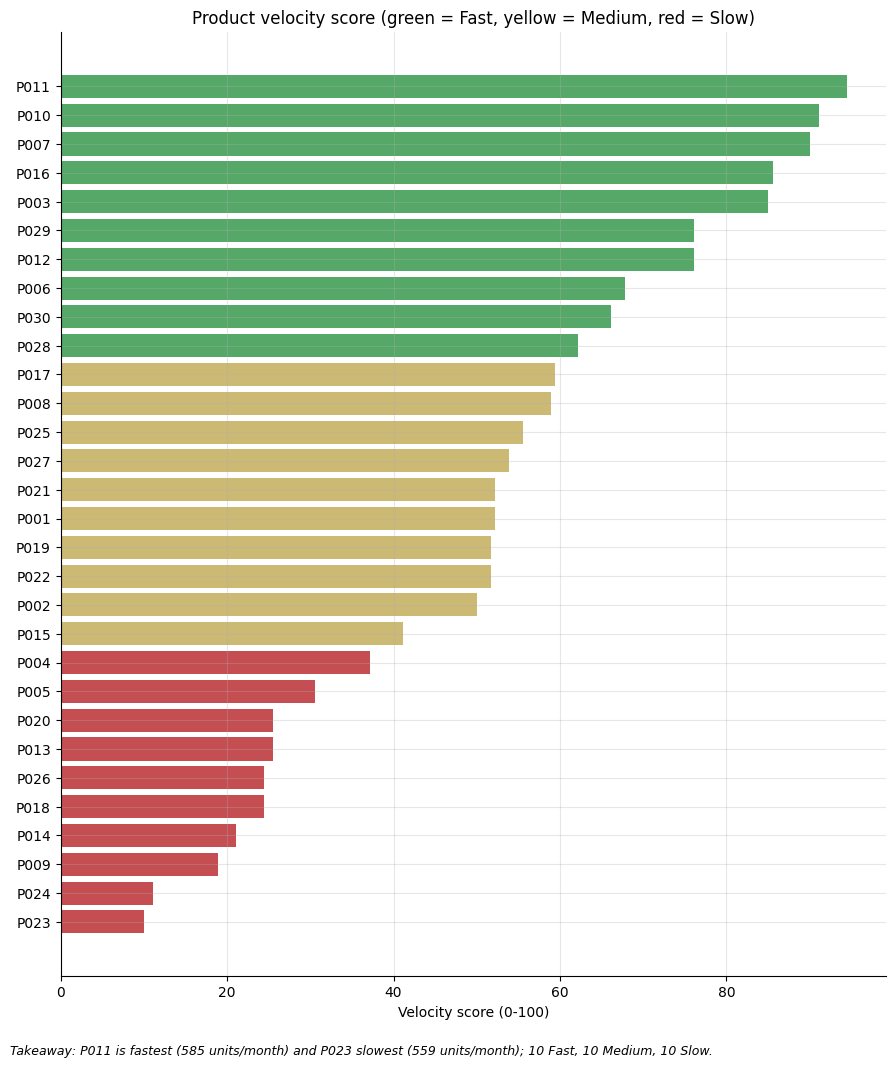

abc_revenue,A,B,C
velocity_class,,,
Fast,3,2,5
Medium,5,0,5
Slow,2,5,3


In [19]:
fig = pa.plot_velocity(vel_prod)
counts = vel_prod["velocity_class"].value_counts()
fastest, slowest = vel_prod.iloc[0], vel_prod.iloc[-1]
pa.save_chart(fig, "b2_velocity_score",
    f"{fastest['product_id']} is fastest ({fastest['units_per_month']:.0f} units/month) and "
    f"{slowest['product_id']} slowest ({slowest['units_per_month']:.0f} units/month); "
    f"{counts.get('Fast', 0)} Fast, {counts.get('Medium', 0)} Medium, {counts.get('Slow', 0)} Slow.", CHART_DIR)

display(pd.crosstab(vel_prod["velocity_class"], vel_prod["abc_revenue"]))

**Reading the output.** A bar for each product, coloured by class. The cross-table below it compares velocity class with revenue ABC class. A fast product that is C (low value) sells often but earns little; a slow product that is A sells rarely but each sale matters. Both deserve different stock policies.

In [20]:
vel_pb = pa.velocity_table(base, ["product_id", "branch_id"], universe=pairs)
vel_pb = pa.attach_labels(vel_pb, tables)
vel_pb.to_csv(WEEK_DIR / "product_branch_velocity.csv", index=False)

print("Product-branch pairs:", len(vel_pb), "| with no sales:", int((vel_pb["velocity_class"] == "No sales").sum()))
display(pd.crosstab(vel_pb["branch"], vel_pb["velocity_class"]))

Product-branch pairs: 180 | with no sales: 0


velocity_class,Fast,Medium,Slow
branch,,,
Ahmedabad,5,25,0
Chennai,30,0,0
Delhi,0,17,13
Hyderabad,0,0,30
Kolkata,25,5,0
Pune,0,13,17


**Reading the output.** Velocity for all 180 product-branch pairs (saved as `product_branch_velocity.csv`) and a count of Fast / Medium / Slow / No-sales pairs per branch. A pair with **no sales** in six years while stock sits in the warehouse is a dead-stock candidate for Week 5.

### Task B2: Summary

| Question | Answer (fill in from the output above) |
|---|---|
| Which products are the fastest movers? |P011, P010, P007, P016, P003, P029, P012, P006, P030, P028|
| Are fast movers also high-value (A) products? | Mostly NO out of the 10, 3 are A, 2 B & 5 C |
| Which branches hold the most slow or no-sales pairs? |NONE |

**Status: COMPLETED** once the table is filled in and `product_velocity.csv` exists.

---
## 4. Task B9: Demand trend and seasonality

**Objective.** Describe how demand changes over time: trend, seasonality and growth.

**Methods.**
* **STL decomposition** splits monthly units into trend + seasonal + residual (period = 12 months).
* **Mann-Kendall test** checks whether the trend is statistically significant. It is run on the de-seasonalised series (trend + residual) so seasonality does not confuse it. **Sen's slope** gives the size of the trend in units per month.
* **Strength measures** (0 to 1): how much of the variation is explained by trend or by seasonality. Near 0 means weak.
* **Growth rates**: last year-on-year change and compound annual growth rate (CAGR) of yearly units.

All 30 products and all 180 product-branch series are tested. Because stock is about 18 times demand, demand may be low and flat; if so, we report that rather than forcing a story.

> The Mann-Kendall test assumes independent observations, which monthly data only roughly meets. Treat p-values as a guide, not proof.

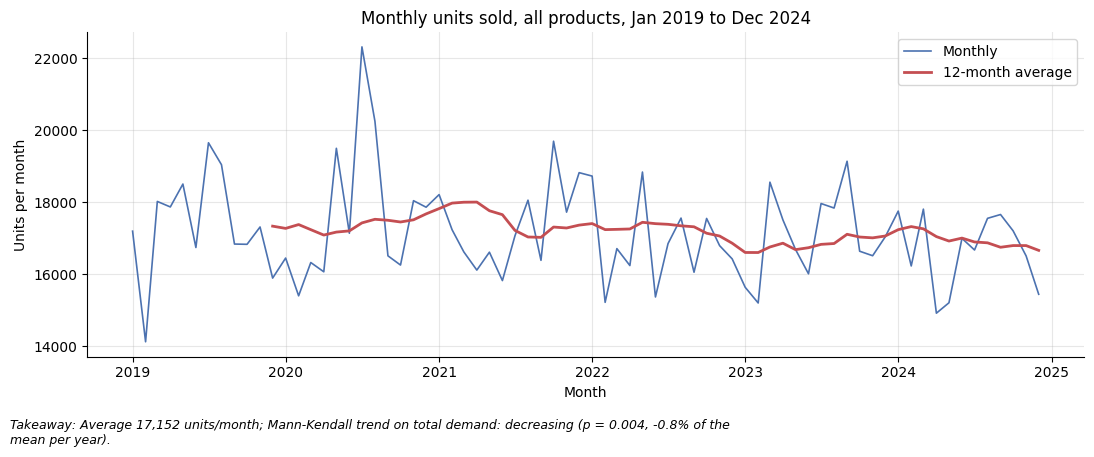

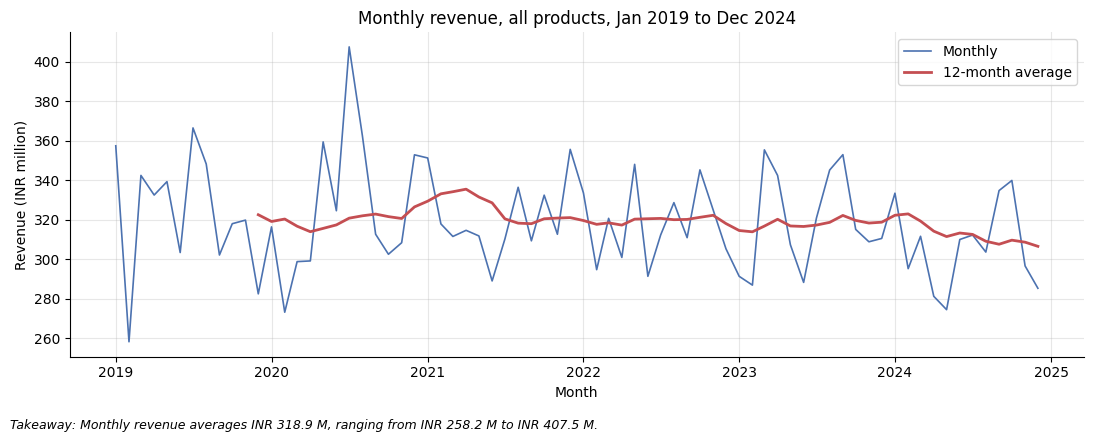

WindowsPath('C:/Users/HP/Desktop/keren/my_project/week-04/charts/b9_monthly_revenue.png')

In [21]:
total_units = m_prod.sum()                                   # all products, per month
total_revenue = base.groupby("order_month")["revenue"].sum().reindex(MONTHS, fill_value=0.0)

fig = pa.plot_monthly(total_units, f"Monthly units sold, all products, {PERIOD}", "Units per month")
trend_all = pa.trend_stats(total_units)
pa.save_chart(fig, "b9_monthly_units",
    f"Average {total_units.mean():,.0f} units/month; Mann-Kendall trend on total demand: {trend_all['mk_trend']} "
    f"(p = {trend_all['mk_p']:.3f}, {trend_all['trend_pct_per_year']:+.1f}% of the mean per year).", CHART_DIR)

fig = pa.plot_monthly(total_revenue, f"Monthly revenue, all products, {PERIOD}", "Revenue (INR million)", scale=1e6)
pa.save_chart(fig, "b9_monthly_revenue",
    f"Monthly revenue averages {pa.inr_m(total_revenue.mean())}, ranging from {pa.inr_m(total_revenue.min())} "
    f"to {pa.inr_m(total_revenue.max())}.", CHART_DIR)

**Reading the output.** Two line charts: units and revenue per month, with a 12-month average. A flat red line means no long-term growth. The takeaway reports the Mann-Kendall verdict for total demand: `no trend` means the data does not support a significant rise or fall.

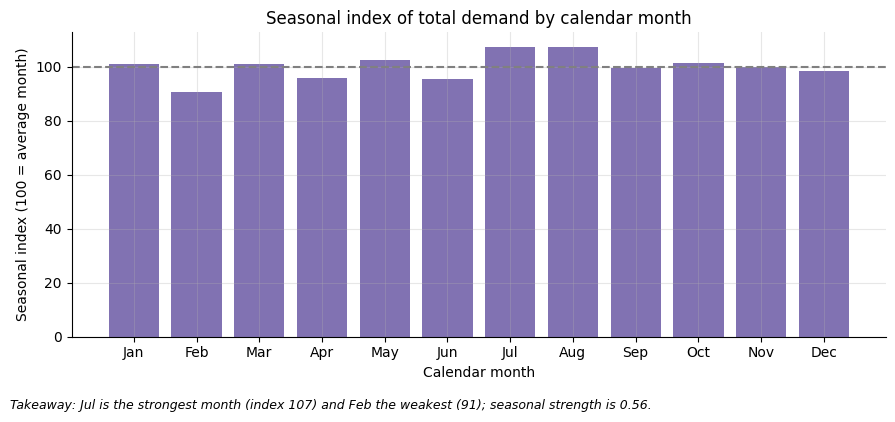

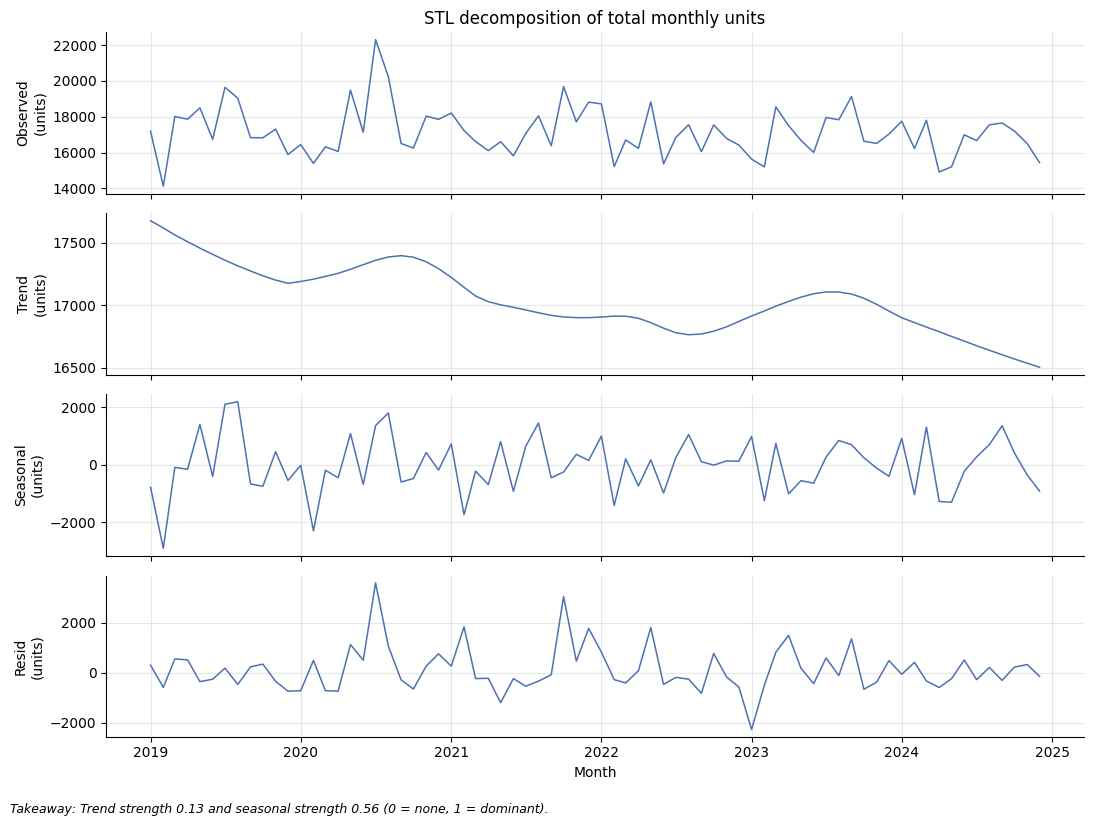

WindowsPath('C:/Users/HP/Desktop/keren/my_project/week-04/charts/b9_stl_total.png')

In [22]:
profile = pa.seasonal_profile(total_units)
comps_all = pa.stl_components(total_units)

fig = pa.plot_seasonal_index(profile, "Seasonal index of total demand by calendar month")
hi, lo = profile.idxmax(), profile.idxmin()
pa.save_chart(fig, "b9_seasonal_index",
    f"{calendar.month_abbr[hi]} is the strongest month (index {profile[hi]:.0f}) and "
    f"{calendar.month_abbr[lo]} the weakest ({profile[lo]:.0f}); seasonal strength is {trend_all['seasonal_strength']:.2f}.", CHART_DIR)

fig = pa.plot_stl(comps_all, "STL decomposition of total monthly units")
pa.save_chart(fig, "b9_stl_total",
    f"Trend strength {trend_all['trend_strength']:.2f} and seasonal strength {trend_all['seasonal_strength']:.2f} "
    f"(0 = none, 1 = dominant).", CHART_DIR)

**Reading the output.** The seasonal index shows each calendar month relative to an average month (100). Bars close to 100 mean no seasonality. The STL chart has four panels: observed, trend, seasonal pattern and residual (what is left). If the residual panel looks as big as the observed panel, most variation is random noise.

In [23]:
trend_prod = pa.attach_labels(pa.trend_table(m_prod), tables)
trend_prod.to_csv(WEEK_DIR / "demand_trends_product.csv", index=False)

m_pb = pa.monthly_matrix(base, ["product_id", "branch_id"], "quantity", MONTHS, universe=pairs)
trend_pb = pa.attach_labels(pa.trend_table(m_pb), tables)
trend_pb.to_csv(WEEK_DIR / "demand_trends_product_branch.csv", index=False)

print("Products by Mann-Kendall result:")
display(trend_prod["mk_trend"].value_counts().to_frame("products"))
print("Product-branch series by Mann-Kendall result:")
display(trend_pb["mk_trend"].value_counts().to_frame("series"))

bins = pd.cut(trend_prod["seasonal_strength"], [-0.01, 0.3, 0.6, 1.0], labels=["weak (<0.3)", "moderate", "strong (>0.6)"])
print("Seasonal strength of products (our own bands):")
display(bins.value_counts().sort_index().to_frame("products"))

Products by Mann-Kendall result:


,products
mk_trend,
no trend,19
decreasing,9
increasing,2


Product-branch series by Mann-Kendall result:


,series
mk_trend,
no trend,134
decreasing,31
increasing,15


Seasonal strength of products (our own bands):


,products
seasonal_strength,
weak (<0.3),15
moderate,15
strong (>0.6),0


**Reading the output.** How many products and product-branch series have a significant increasing, decreasing or no trend, and how strongly seasonal the products are (bands are our own convention). Expect most series to show *no trend* if demand is flat. The detailed tables are saved as `demand_trends_product.csv` and `demand_trends_product_branch.csv`.

In [24]:
cols = ["product_id", "product_name", "mean_monthly_units", "mk_trend", "mk_p", "trend_pct_per_year",
        "trend_strength", "seasonal_strength", "peak_month", "low_month"]
print("Products with the strongest seasonality:")
display(trend_prod.sort_values("seasonal_strength", ascending=False)[cols].head(5))
print("Products with a significant trend:")
sig = trend_prod[trend_prod["mk_trend"] != "no trend"].sort_values("trend_pct_per_year")
display(sig[cols] if len(sig) else pd.DataFrame({"note": ["No product has a significant trend."]}))

Products with the strongest seasonality:


,product_id,product_name,mean_monthly_units,mk_trend,mk_p,trend_pct_per_year,trend_strength,seasonal_strength,peak_month,low_month
3,P004,Track Chain TC-45,567.93,no trend,0.05,-1.59,0.22,0.55,Jul,Apr
24,P025,Cabin Glass CG-20,570.71,no trend,0.06,-1.92,0.15,0.48,Mar,Sep
14,P015,Engine Block EB-600,566.88,no trend,0.06,-1.35,0.13,0.42,Oct,Nov
8,P009,Starter Motor SM-700,563.15,decreasing,0.00,-2.04,0.07,0.42,Aug,Feb
20,P021,Boom Cylinder BC-400,581.44,no trend,0.43,-0.57,0.08,0.42,Jun,Feb


Products with a significant trend:


,product_id,product_name,mean_monthly_units,mk_trend,mk_p,trend_pct_per_year,trend_strength,seasonal_strength,peak_month,low_month
11,P012,Brake Pad BP-40,577.07,decreasing,0.00,-2.99,0.14,0.35,May,Sep
18,P019,Swing Motor SWM-350,576.99,decreasing,0.00,-2.85,0.03,0.24,Sep,Jun
9,P010,Turbocharger TB-900,587.39,decreasing,0.00,-2.27,0.04,0.29,Jul,Feb
27,P028,Light Assembly LA-18,573.50,decreasing,0.00,-2.17,0.13,0.25,Mar,Feb
4,P005,Fuel Injector FI-220,562.22,decreasing,0.01,-2.16,0.06,0.22,Aug,Mar
8,P009,Starter Motor SM-700,563.15,decreasing,0.00,-2.04,0.07,0.42,Aug,Feb
19,P020,Pivot Pin PP-12,568.26,decreasing,0.00,-2.03,0.07,0.38,Aug,Dec
6,P007,Hydraulic Hose HH-60,585.50,decreasing,0.02,-1.29,0.02,0.03,May,Mar
0,P001,Hydraulic Pump HP-300,573.67,decreasing,0.05,-1.22,0.00,0.30,Jul,Feb
23,P024,Track Roller TR-60,548.42,increasing,0.03,1.28,0.03,0.34,Jul,Feb


**Reading the output.** The products with the most seasonal demand (and their peak and low months), and any products whose trend is statistically significant with the change in % of average demand per year. If the second table is empty, no product shows a reliable trend.

In [37]:
growth_prod = pa.attach_labels(pa.growth_table(m_prod), tables)
growth_prod = growth_prod.merge(abc_xyz[["product_id", "abc_revenue"]], on="product_id", how="left")
growth_prod.to_csv(WEEK_DIR / "demand_growth_by_product.csv", index=False)

total_growth = pa.growth_table(total_units.to_frame("all_products").T).iloc[0]
print(f"Total demand: last year-on-year {total_growth['yoy_last_pct']:+.1f}%, CAGR {total_growth['cagr_pct']:+.1f}%")

show = ["product_id", "product_name", "abc_revenue", "yoy_last_pct", "cagr_pct"]
print("Fastest-growing products (CAGR):")
display(growth_prod.sort_values("cagr_pct", ascending=False)[show].head(5))
print("Fastest-declining products (CAGR):")
display(growth_prod.sort_values("cagr_pct")[show].head(5))

Total demand: last year-on-year -2.3%, CAGR -0.8%
Fastest-growing products (CAGR):


,product_id,product_name,abc_revenue,yoy_last_pct,cagr_pct
5,P006,Alternator ALT-500,B,-1.22,2.79
23,P024,Track Roller TR-60,B,-2.43,1.27
13,P014,Transmission Assembly TA-800,A,3.74,1.08
28,P029,Pressure Sensor PS-90,C,11.23,1.00
15,P016,Radiator RD-250,B,3.87,1.00


Fastest-declining products (CAGR):


,product_id,product_name,abc_revenue,yoy_last_pct,cagr_pct
11,P012,Brake Pad BP-40,C,-6.57,-3.31
18,P019,Swing Motor SWM-350,A,-15.64,-2.98
9,P010,Turbocharger TB-900,A,-10.92,-2.68
4,P005,Fuel Injector FI-220,B,-13.31,-2.29
3,P004,Track Chain TC-45,A,-1.31,-2.27


**Reading the output.** Yearly units for each product are saved to `demand_growth_by_product.csv`. The tables list the fastest-growing and fastest-declining products by CAGR, with the last year-on-year change. Check whether the big movers are A products (important) or C products (minor), and whether their growth is also *significant* in the Mann-Kendall table above.

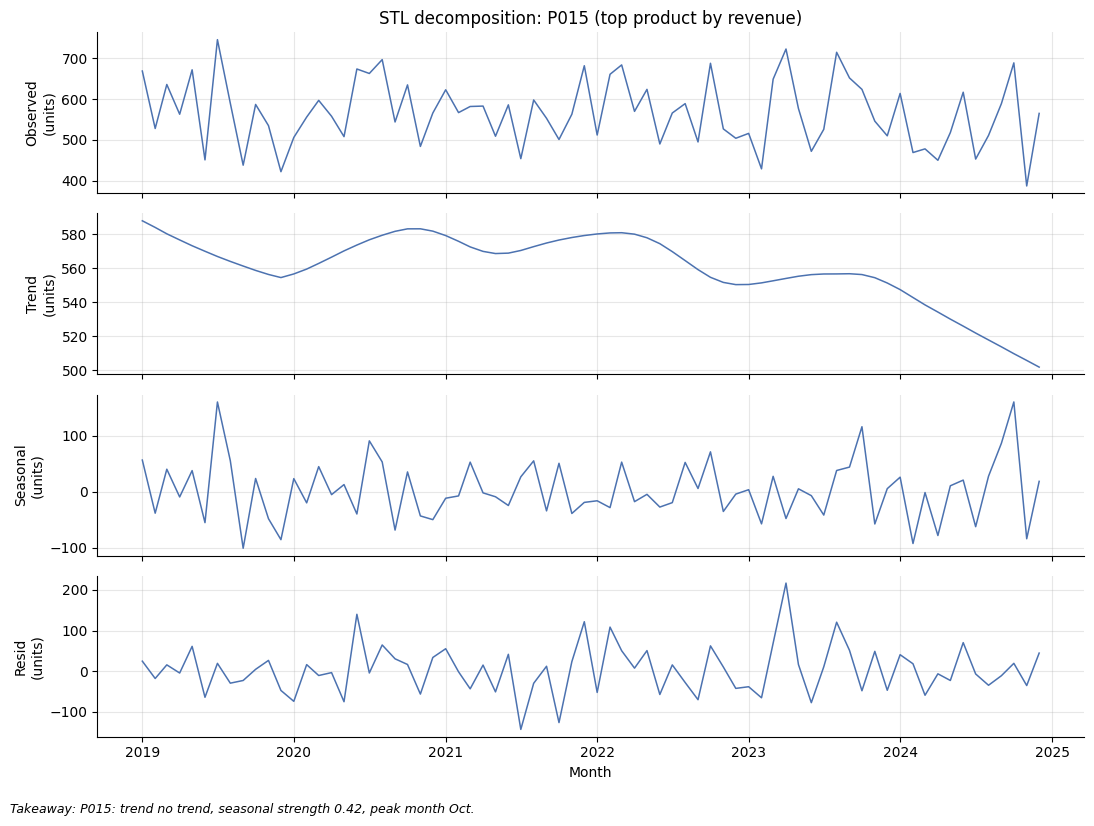

WindowsPath('C:/Users/HP/Desktop/keren/my_project/week-04/charts/b9_stl_top_product.png')

In [26]:
top_pid = by_product.iloc[0]["product_id"]
comps_top = pa.stl_components(m_prod.loc[top_pid])
stats_top = trend_prod.set_index("product_id").loc[top_pid]
fig = pa.plot_stl(comps_top, f"STL decomposition: {top_pid} (top product by revenue)")
pa.save_chart(fig, "b9_stl_top_product",
    f"{top_pid}: trend {stats_top['mk_trend']}, seasonal strength {stats_top['seasonal_strength']:.2f}, "
    f"peak month {stats_top['peak_month']}.", CHART_DIR)

**Reading the output.** The same decomposition for the top revenue product, to see whether the portfolio-level pattern also holds for the product that matters most.

### Task B9: Summary

| Question | Answer (fill in from the output above) |
|---|---|
| Is total demand growing, flat or falling? |falling |
| Is there a seasonal pattern? Which months peak and dip? |YES, July is the peak month and Feburary is the dip |
| How many products have a significant trend? |11 |
| Which products grow or decline fastest, and do they matter (A or C)? | 9 product grow fastest and 21 decline and it doesn't matter |
| What does this mean for forecasting in Week 9? |Account for declining demand, seasonality and product-specfic trends |

**Status: COMPLETED** once the table is filled in.

---
## 5. Key findings, conclusions and next steps

### 5.1 Key findings (generated from the results)

Copy these lines into the results summary at the top and into the insight brief (`reports/week04_product_insights.docx`).

In [27]:
trend_counts = trend_prod["mk_trend"].value_counts().to_dict()
vc = vel_prod["velocity_class"].value_counts().to_dict()
findings = [
    f"Scope: {kpis.loc['delivered_orders','value']:,} delivered orders, {PERIOD}; revenue {pa.inr_m(kpis.loc['revenue_inr','value'])} "
    f"(before GST), gross margin {kpis.loc['gross_margin_pct','value']:.1f}% (estimated from product master cost).",
    f"Concentration: {n80_rev} of {n_prod} products generate 80% of revenue; {n80_mar} generate 80% of margin; "
    f"{len(set(top_rev) & set(top_mar))} products are in both lists.",
    f"Top product: {by_product.iloc[0]['product_id']} ({by_product.iloc[0]['product_name']}) with "
    f"{by_product.iloc[0]['revenue_share_pct']:.1f}% of revenue.",
    f"Branches: {dim_tables['branch'].iloc[0]['branch']} leads with {dim_tables['branch'].iloc[0]['revenue_share_pct']:.1f}% of revenue; "
    f"products needed for 80% range from {branch_pareto['products_for_80pct'].min()} to {branch_pareto['products_for_80pct'].max()} by branch.",
    f"ABC-XYZ: {n_a} A products by revenue ({n_ax} are AX: high value, steady); {n_z} products have erratic (Z) demand "
    f"(cut-offs X < {X_CUT}, Y < {Y_CUT}).",
    f"Velocity: {vc.get('Fast', 0)} Fast, {vc.get('Medium', 0)} Medium, {vc.get('Slow', 0)} Slow products; "
    f"{int((vel_pb['velocity_class'] == 'No sales').sum())} of 180 product-branch pairs had no sales.",
    f"Trend: total demand shows '{trend_all['mk_trend']}' (p = {trend_all['mk_p']:.3f}); "
    f"{trend_counts.get('increasing', 0)} products increasing, {trend_counts.get('decreasing', 0)} decreasing, "
    f"{trend_counts.get('no trend', 0)} with no significant trend.",
    f"Seasonality: total demand seasonal strength {trend_all['seasonal_strength']:.2f}; "
    f"peak month {calendar.month_abbr[hi]}, weakest month {calendar.month_abbr[lo]}.",
    f"Growth: total demand last year-on-year {total_growth['yoy_last_pct']:+.1f}%, CAGR {total_growth['cagr_pct']:+.1f}%.",
]
for i, f in enumerate(findings, 1):
    print(f"{i}. {f}")

1. Scope: 18,033 delivered orders, Jan 2019 to Dec 2024; revenue INR 22,959.0 M (before GST), gross margin 21.6% (estimated from product master cost).
2. Concentration: 10 of 30 products generate 80% of revenue; 12 generate 80% of margin; 10 products are in both lists.
3. Top product: P015 (Engine Block EB-600) with 21.2% of revenue.
4. Branches: Chennai leads with 20.4% of revenue; products needed for 80% range from 10 to 10 by branch.
5. ABC-XYZ: 10 A products by revenue (10 are AX: high value, steady); 0 products have erratic (Z) demand (cut-offs X < 0.5, Y < 1.0).
6. Velocity: 10 Fast, 10 Medium, 10 Slow products; 0 of 180 product-branch pairs had no sales.
7. Trend: total demand shows 'decreasing' (p = 0.004); 2 products increasing, 9 decreasing, 19 with no significant trend.
8. Seasonality: total demand seasonal strength 0.56; peak month Jul, weakest month Feb.
9. Growth: total demand last year-on-year -2.3%, CAGR -0.8%.


**Reading the output.** Nine plain-language findings, each built from the numbers computed above. Add the *so what* for each in the insight brief: the recommendation, expected impact and priority (high / medium / low), following Appendix B of the plan.

### 5.2 Conclusions

*Write 3 to 5 sentences in your own words after reading the output: which products matter most, whether demand is steady or seasonal, and what that implies for stock policy.*

### 5.3 Limitations

* Gross margin uses the product master `unit_cost`, not actual purchase cost, so it is an estimate.
* With 30 products the Pareto and ABC splits are coarse; one product moves the shares noticeably.
* XYZ cut-offs are a convention; the classification changes if they change.
* Trend tests on monthly data are approximate (autocorrelation, short series for product-branch pairs).
* Sales demand is low relative to stock (about 1 : 18 in the Week 2 ledger), so any forecast built on it must be benchmarked against simple baselines.

### 5.4 Next steps

1. **Insight brief** (`reports/week04_product_insights.docx`): top findings with one supporting number each, recommendation, impact, priority.
2. **Week 5 (inventory health):** reuse `product_velocity.csv` and `product_branch_velocity.csv` for slow and dead stock; compare AX products' stock cover with their demand.
3. **Week 9 (forecasting):** use `abc_xyz_product_branch.csv` to choose a method per class and `demand_trends_product_branch.csv` to decide where seasonal models are worth it.
4. **Week 11 (dashboards):** the classification and velocity CSVs feed the Product Performance dashboard.

---

**Prepared by:** Keren Oyem · Data Analyst · CadetX Virtual Work Experience · Heavy Supplier, Inventory & Warehouse Analytics